<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%2013/Latihan%20Praktikum%2013_Machine%20Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13.11 Implementasi Python — CNN & Transfer Learning (MobileNetV2)



## Praktikum 13.1 Persiapan Library

In [ ]:
import os, time, shutil, random, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU terdeteksi: []


## Praktikum 13.2 Import Dataset

Membuat struktur folder `dataset/train/<kelas>` dan `dataset/val/<kelas>` dari dataset bunga (hanya dilakukan sekali).

In [ ]:
EPOCHS_TL = 15            # epoch Praktikum 13.4 (sesuai buku)

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
arsip = keras.utils.get_file(origin=url, extract=True)
sumber = pathlib.Path(arsip).with_suffix("")            # .../flower_photos
if not sumber.is_dir():                                   # cadangan jika lokasi berbeda
    sumber = next(p for p in pathlib.Path(arsip).parent.rglob("flower_photos") if p.is_dir())

if not os.path.exists("dataset"):
    rnd = random.Random(42)
    for kelas in sorted(p.name for p in sumber.iterdir() if p.is_dir()):
        berkas = sorted((sumber / kelas).glob("*.jpg")); rnd.shuffle(berkas)
        n_val = int(0.2 * len(berkas))
        for i, f in enumerate(berkas):
            tujuan = pathlib.Path("dataset") / ("val" if i < n_val else "train") / kelas
            tujuan.mkdir(parents=True, exist_ok=True); shutil.copy(f, tujuan)
for bagian in ["train", "val"]:
    print(bagian, {k.name: len(list(k.glob("*.jpg"))) for k in sorted(pathlib.Path("dataset", bagian).iterdir())})

# Contoh menggunakan dataset citra terorganisir dalam folder per kelas
# (struktur: dataset/train/kelas_1, dataset/train/kelas_2, dst.)
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory("dataset/train",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory("dataset/val",
    image_size=IMG_SIZE, batch_size=BATCH_SIZE)
jumlah_kelas = len(train_ds.class_names)
print("Kelas:", train_ds.class_names, "| jumlah kelas:", jumlah_kelas)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
train {'daisy': 507, 'dandelion': 719, 'roses': 513, 'sunflowers': 560, 'tulips': 640}
val {'daisy': 126, 'dandelion': 179, 'roses': 128, 'sunflowers': 139, 'tulips': 159}
Found 2939 files belonging to 5 classes.
Found 731 files belonging to 5 classes.
Kelas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] | jumlah kelas: 5


## Praktikum 13.3 Preprocessing

In [ ]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x),
                                      y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

# (tambahan) mempercepat pembacaan data
train_ds = train_ds.cache().prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

## Praktikum 13.4 Training Model (Transfer Learning dengan MobileNetV2)

In [ ]:
base_model = MobileNetV2(input_shape=IMG_SIZE+(3,),
    include_top=False, weights="imagenet")
base_model.trainable = False  # Feature extraction: bekukan
                              # bobot pre-trained

model = keras.Sequential([ base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas,
    activation="softmax") ])

model.compile(optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

mulai = time.time()
history = model.fit(train_ds, validation_data=val_ds,
    epochs=EPOCHS_TL)
waktu_tl_bunga = time.time() - mulai
print(f"Waktu pelatihan: {waktu_tl_bunga:.0f} detik")

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 76s 768ms/step - accuracy: 0.7884 - loss: 0.5847 - val_accuracy: 0.8700 - val_loss: 0.3781
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 77s 713ms/step - accuracy: 0.9078 - loss: 0.2641 - val_accuracy: 0.8741 - val_loss: 0.3656
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 82s 709ms/step - accuracy: 0.9435 - loss: 0.1747 - val_accuracy: 0.8687 - val_loss: 0.3712
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 66s 719ms/step - accuracy: 0.9629 - loss: 0.1149 - val_accuracy: 0.8714 - val_loss: 0.4113
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 66s 716ms/step - accuracy: 0.9687 - loss: 0.0986 - val_accuracy: 0.8700 - val_loss: 0.4067
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 64s 698ms/step - accuracy: 0.9792 - loss: 0.0715 - val_accuracy: 0.8741 - val_loss: 0.4105
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 64s 703ms/step - accuracy: 0.9847 - loss: 0.0543 - val_accuracy: 0.8810 - val_loss: 0.4184
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 82s 703ms/step - accuracy: 0.9864 - loss: 0.0429 - val_accu

## Praktikum 13.5 Evaluasi

In [ ]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc:.3f}")

total = model.count_params()
trainable = int(sum(np.prod(v.shape) for v in model.trainable_weights))
print(f"Parameter total: {total:,} | dilatih: {trainable:,} | dibekukan: {total - trainable:,}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.8851 - loss: 0.4648
Akurasi Validasi: 0.885
Parameter total: 2,422,597 | dilatih: 164,613 | dibekukan: 2,257,984


## Praktikum 13.6 Visualisasi

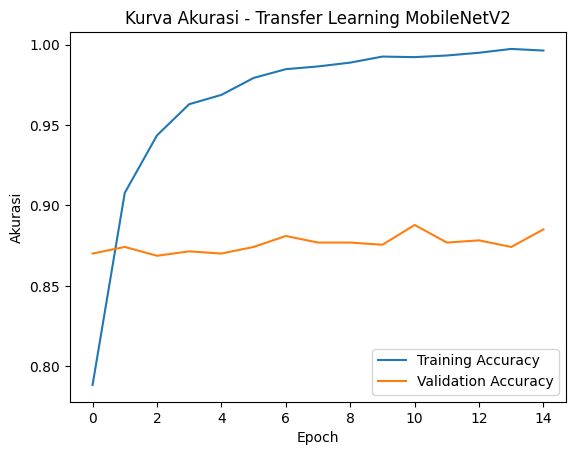

Training accuracy akhir  : 0.996
Validation accuracy akhir: 0.885
Epoch dengan val_accuracy tertinggi: 11 | nilai: 0.888
Gap train - val (akhir): 0.111


In [ ]:
plt.plot(history.history["accuracy"],
    label="Training Accuracy")
plt.plot(history.history["val_accuracy"]
,
    label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend()
plt.show()

h = history.history
print("Training accuracy akhir  :", round(h["accuracy"][-1], 3))
print("Validation accuracy akhir:", round(h["val_accuracy"][-1], 3))
print("Epoch dengan val_accuracy tertinggi:", int(np.argmax(h["val_accuracy"])) + 1,
      "| nilai:", round(max(h["val_accuracy"]), 3))
print("Gap train - val (akhir):", round(h["accuracy"][-1] - h["val_accuracy"][-1], 3))

### 13.11.1 Interpretasi

Karena bobot MobileNetV2 dibekukan (*feature extraction*), hanya layer klasifikasi baru (Dense 128 dan Dense keluaran) yang dilatih, sehingga pelatihan jauh lebih cepat dibanding melatih CNN dari nol. Cara membaca hasil di atas: (1) bandingkan *Training* dan *Validation Accuracy*; gap besar berarti overfitting, (2) bila akurasi validasi sudah mendatar sebelum epoch 15, menambah epoch tidak banyak membantu.

**Opsional, fine-tuning** (langkah lanjutan yang disebut buku bila akurasi validasi masih kurang): buka beberapa layer terakhir `base_model` dan latih ulang dengan *learning rate* sangat kecil. Sel di bawah mencetak akurasi sebelum dan sesudah fine-tuning agar bisa dibandingkan langsung.

In [ ]:
# OPSIONAL - Fine-tuning (butuh GPU agar tidak lambat)
EPOCHS_FT = 5
acc_sebelum = val_acc
base_model.trainable = True
for layer in base_model.layers[:-30]:      # bekukan semua kecuali 30 layer terakhir
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5),   # learning rate sangat kecil
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ft = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, verbose=2)
print(f"Akurasi validasi sebelum fine-tuning: {acc_sebelum:.3f}")
print(f"Akurasi validasi setelah fine-tuning: {ft.history['val_accuracy'][-1]:.3f}")

Epoch 1/5
92/92 - 98s - 1s/step - accuracy: 0.3668 - loss: 1.6938 - val_accuracy: 0.1765 - val_loss: 4.1109
Epoch 2/5
92/92 - 137s - 1s/step - accuracy: 0.4964 - loss: 1.2956 - val_accuracy: 0.1751 - val_loss: 4.7947
Epoch 3/5
92/92 - 92s - 1s/step - accuracy: 0.5488 - loss: 1.1440 - val_accuracy: 0.1751 - val_loss: 5.5151
Epoch 4/5
92/92 - 92s - 1s/step - accuracy: 0.6111 - loss: 1.0326 - val_accuracy: 0.1751 - val_loss: 5.8532
Epoch 5/5
92/92 - 82s - 894ms/step - accuracy: 0.6434 - loss: 0.9520 - val_accuracy: 0.1751 - val_loss: 5.7712
Akurasi validasi sebelum fine-tuning: 0.885
Akurasi validasi setelah fine-tuning: 0.175


---
## 13.12 Latihan Praktikum

### Praktikum 1: CNN Sederhana dari Nol (Praktikum 13.7) pada CIFAR-10

In [ ]:
import time
import numpy as np
from tensorflow import keras

EPOCHS_CNN = 15

(x_raw_tr, y_tr), (x_raw_te, y_te) = keras.datasets.cifar10.load_data()
y_tr, y_te = y_tr.ravel(), y_te.ravel()
x_tr = x_raw_tr.astype("float32") / 255.0
x_te = x_raw_te.astype("float32") / 255.0
nama_kelas = ["pesawat", "mobil", "burung", "kucing", "rusa", "anjing", "katak", "kuda", "kapal", "truk"]
print("Data latih:", x_tr.shape, "| data uji:", x_te.shape)

def buat_cnn():
    m = keras.Sequential([ keras.Input(shape=(32, 32, 3)),
        keras.layers.Conv2D(32, (3, 3), activation="relu"),
        keras.layers.MaxPooling2D((2, 2)),
        keras.layers.Conv2D(64, (3, 3), activation="relu"),
        keras.layers.MaxPooling2D((2, 2)),
        keras.layers.Flatten(), keras.layers.Dense(64,
        activation="relu"),
        keras.layers.Dense(10, activation="softmax") ])
    m.compile(optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    return m

# Latih pada dataset CIFAR-10 (keras.datasets.cifar10) dan
# bandingkan dengan hasil Transfer Learning
keras.utils.set_random_seed(42)
model_cnn = buat_cnn()
model_cnn.summary()
mulai = time.time()
h_cnn_penuh = model_cnn.fit(x_tr, y_tr, validation_split=0.1, epochs=EPOCHS_CNN, batch_size=64, verbose=2)
waktu_cnn_penuh = time.time() - mulai
loss_cnn_penuh, acc_cnn_penuh = model_cnn.evaluate(x_te, y_te, verbose=0)
print(f"\nCNN dari nol (50.000 citra latih): akurasi uji = {acc_cnn_penuh:.3f}, waktu = {waktu_cnn_penuh:.0f} detik")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1556s 9us/step
Data latih: (50000, 32, 32, 3) | data uji: (10000, 32, 32, 3)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,562 (654.54 KB)

 Trainable params: 167,562 (654.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
704/704 - 17s - 24ms/step - accuracy: 0.4515 - loss: 1.5260 - val_accuracy: 0.5460 - val_loss: 1.2878
Epoch 2/15
704/704 - 8s - 11ms/step - accuracy: 0.5819 - loss: 1.1909 - val_accuracy: 0.5924 - val_loss: 1.1495
Epoch 3/15
704/704 - 3s - 4ms/step - accuracy: 0.6315 - loss: 1.0600 - val_accuracy: 0.6412 - val_loss: 1.0310
Epoch 4/15
704/704 - 3s - 4ms/step - accuracy: 0.6606 - loss: 0.9772 - val_accuracy: 0.6554 - val_loss: 0.9858
Epoch 5/15
704/704 - 3s - 4ms/step - accuracy: 0.6831 - loss: 0.9129 - val_accuracy: 0.6652 - val_loss: 0.9564
Epoch 6/15
704/704 - 3s - 4ms/step - accuracy: 0.7025 - loss: 0.8588 - val_accuracy: 0.6726 - val_loss: 0.9412
Epoch 7/15
704/704 - 3s - 4ms/step - accuracy: 0.7189 - loss: 0.8133 - val_accuracy: 0.6754 - val_loss: 0.9341
Epoch 8/15
704/704 - 3s - 4ms/step - accuracy: 0.7348 - loss: 0.7723 - val_accuracy: 0.6824 - val_loss: 0.9230
Epoch 9/15
704/704 - 5s - 7ms/step - accuracy: 0.7467 - loss: 0.7378 - val_accuracy: 0.6820 - val_loss: 0.933

In [ ]:
import matplotlib.pyplot as plt

plt.plot(h_cnn_penuh.history["accuracy"], label="Training Accuracy")
plt.plot(h_cnn_penuh.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Akurasi"); plt.title("CNN dari nol pada CIFAR-10 (data penuh)")
plt.legend(); plt.show()
hh = h_cnn_penuh.history
print("Training acc akhir:", round(hh["accuracy"][-1], 3), "| Validation acc akhir:", round(hh["val_accuracy"][-1], 3),
      "| gap:", round(hh["accuracy"][-1] - hh["val_accuracy"][-1], 3))
print("val_loss terendah pada epoch", int(np.argmin(hh["val_loss"])) + 1, "dari", EPOCHS_CNN)

NameError: name 'h_cnn_penuh' is not defined

Perbandingan dengan Transfer Learning pada **data CIFAR-10 yang sama** dilakukan pada Praktikum 2 di bawah (subset kecil, sesuai kondisi data terbatas).

### Praktikum 2: CNN dari Nol vs Transfer Learning MobileNetV2 (subset 500 citra per kelas)

CIFAR-10 diambil 500 citra per kelas (5.000 citra latih) dan dievaluasi pada 200 citra per kelas (2.000 citra uji, terpisah dari data latih). Kedua pendekatan memakai data yang sama dan jumlah epoch yang sama.

In [ ]:
N_PER_CLASS = 500
N_TEST_PER_CLASS = 200
EPOCHS_SUB = 20
rng = np.random.default_rng(42)
def ambil(y, n):
    idx = np.concatenate([rng.choice(np.where(y == k)[0], n, replace=False) for k in range(10)])
    rng.shuffle(idx); return idx
i_tr, i_te = ambil(y_tr, N_PER_CLASS), ambil(y_te, N_TEST_PER_CLASS)
xs_tr, ys_tr = x_raw_tr[i_tr], y_tr[i_tr]          # uint8 0-255
xs_te, ys_te = x_raw_te[i_te], y_te[i_te]
print("Subset latih:", xs_tr.shape, np.bincount(ys_tr), "| subset uji:", xs_te.shape)

def hitung_param(m):
    total = m.count_params()
    train = int(sum(np.prod(v.shape) for v in m.trainable_weights))
    return total, train

# --- (a) CNN dari nol (masukan 32x32, nilai 0-1) ---
keras.utils.set_random_seed(42)
cnn_sub = buat_cnn()
mulai = time.time()
h_cnn = cnn_sub.fit(xs_tr.astype("float32") / 255.0, ys_tr,
                    validation_data=(xs_te.astype("float32") / 255.0, ys_te),
                    epochs=EPOCHS_SUB, batch_size=32, verbose=2)
waktu_cnn = time.time() - mulai

# --- (b) Transfer Learning MobileNetV2 (masukan diperbesar ke 96x96) ---
UKURAN_TL = (96, 96)
def siapkan(x, y, acak):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if acak: ds = ds.shuffle(len(x), seed=42)
    return (ds.batch(32)
              .map(lambda a, b: (preprocess_input(tf.image.resize(tf.cast(a, tf.float32), UKURAN_TL)), b))
              .cache().prefetch(tf.data.AUTOTUNE))
ds_tr, ds_te = siapkan(xs_tr, ys_tr, True), siapkan(xs_te, ys_te, False)

keras.utils.set_random_seed(42)
dasar = MobileNetV2(input_shape=UKURAN_TL + (3,), include_top=False, weights="imagenet")
dasar.trainable = False
tl_sub = keras.Sequential([dasar, keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax")])
tl_sub.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mulai = time.time()
h_tl = tl_sub.fit(ds_tr, validation_data=ds_te, epochs=EPOCHS_SUB, verbose=2)
waktu_tl = time.time() - mulai
print("selesai")

In [ ]:
# Tabel perbandingan
p_cnn, p_cnn_t = hitung_param(cnn_sub)
p_tl, p_tl_t = hitung_param(tl_sub)
hc, ht = h_cnn.history, h_tl.history
tabel = pd.DataFrame({
    "Akurasi uji (epoch akhir)": [hc["val_accuracy"][-1], ht["val_accuracy"][-1]],
    "Akurasi uji tertinggi": [max(hc["val_accuracy"]), max(ht["val_accuracy"])],
    "Akurasi latih (akhir)": [hc["accuracy"][-1], ht["accuracy"][-1]],
    "Gap latih - uji": [hc["accuracy"][-1] - hc["val_accuracy"][-1], ht["accuracy"][-1] - ht["val_accuracy"][-1]],
    "Waktu pelatihan (detik)": [waktu_cnn, waktu_tl],
    "Parameter total": [p_cnn, p_tl],
    "Parameter yang dilatih": [p_cnn_t, p_tl_t],
}, index=["CNN dari nol (32x32)", "Transfer Learning MobileNetV2 (96x96)"])
display(tabel.round(3))
print(f"Referensi: CNN dari nol dengan data penuh (50.000 citra): akurasi uji {acc_cnn_penuh:.3f}, waktu {waktu_cnn_penuh:.0f} detik")

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, h, judul in zip(ax, [hc, ht], ["CNN dari nol", "Transfer Learning MobileNetV2"]):
    a.plot(h["accuracy"], label="Latih"); a.plot(h["val_accuracy"], label="Uji"); a.set_title(judul); a.set_xlabel("Epoch")
ax[0].set_ylabel("Akurasi"); ax[0].legend(); plt.tight_layout(); plt.show()

In [ ]:
# Analisis otomatis dari angka di atas
a_c, a_t = hc["val_accuracy"][-1], ht["val_accuracy"][-1]
g_c, g_t = hc["accuracy"][-1] - a_c, ht["accuracy"][-1] - a_t
print("ANALISIS PERBANDINGAN")
print(f"1. Akurasi: Transfer Learning {a_t:.3f} vs CNN dari nol {a_c:.3f} -> selisih {abs(a_t - a_c) * 100:.1f} poin, "
      f"{'Transfer Learning lebih akurat' if a_t > a_c else 'CNN dari nol lebih akurat'} "
      f"(uji = {len(ys_te)} citra, 1 citra = {100 / len(ys_te):.2f} poin)."
      + (" Selisih di bawah 2 poin: belum tentu bermakna." if abs(a_t - a_c) < 0.02 else ""))
print(f"2. Waktu pelatihan ({EPOCHS_SUB} epoch): CNN {waktu_cnn:.0f} dtk vs Transfer Learning {waktu_tl:.0f} dtk "
      f"-> {'CNN lebih cepat' if waktu_cnn < waktu_tl else 'Transfer Learning lebih cepat'} "
      f"(x{max(waktu_cnn, waktu_tl) / max(1e-9, min(waktu_cnn, waktu_tl)):.1f}). Catatan: Transfer Learning tetap harus menjalankan forward pass "
      f"melalui MobileNetV2 pada citra 96x96 di setiap epoch meski bobotnya dibekukan.")
print(f"3. Parameter: CNN {p_cnn:,} total ({p_cnn_t:,} dilatih) vs Transfer Learning {p_tl:,} total ({p_tl_t:,} dilatih). "
      f"Jumlah parameter yang DILATIH relatif sebanding; yang berbeda adalah {p_tl - p_tl_t:,} parameter terlatih (ImageNet) yang dibekukan.")
print(f"4. Overfitting (gap latih - uji): CNN {g_c:.3f} vs Transfer Learning {g_t:.3f} "
      f"-> {'CNN lebih overfit' if g_c > g_t else 'Transfer Learning lebih overfit'}.")
print(f"5. Efek jumlah data: CNN dengan 5.000 citra {a_c:.3f} vs CNN dengan 50.000 citra {acc_cnn_penuh:.3f} "
      f"-> data lebih banyak {'meningkatkan' if acc_cnn_penuh > a_c else 'tidak meningkatkan'} akurasi CNN dari nol sebesar {abs(acc_cnn_penuh - a_c) * 100:.1f} poin.")

#### Cara menuliskan kesimpulan Praktikum 2

Salin angka dari tabel dan analisis otomatis di atas ke laporan, lalu bahas tiga hal yang diminta soal:

- **Akurasi:** pada data terbatas, fitur ImageNet yang sudah dilatih umumnya memberi representasi visual yang lebih kaya daripada CNN kecil yang dilatih dari nol, sehingga transfer learning cenderung lebih akurat. Periksa apakah itu terjadi pada angka Anda, dan perhatikan juga bahwa CIFAR-10 berukuran kecil (32×32) lalu diperbesar ke 96×96, yang membatasi manfaat fitur ImageNet.
- **Waktu pelatihan:** CNN kecil biasanya lebih cepat per epoch dibanding MobileNetV2, walaupun bobotnya dibekukan, karena MobileNetV2 tetap harus dihitung maju pada citra yang lebih besar. Keunggulan transfer learning ada pada **jumlah data dan epoch yang dibutuhkan**, bukan selalu pada waktu per epoch.
- **Jumlah parameter:** bandingkan *parameter total* dan *parameter yang dilatih*. Yang dilatih pada keduanya sebanding (±165 ribu); transfer learning menambah jutaan parameter beku dari ImageNet.

Jawaban final harus mengikuti angka dari hasil eksekusi Anda sendiri, karena waktu bergantung pada jenis GPU/CPU di Colab dan akurasi dapat bervariasi antar eksekusi.